# Import libraries

In [1]:
import numpy as np
import sympy as sym
from sympy.vector import cross
from scipy.integrate import quad
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Define constants

## Physical

In [2]:
# electron charge
qe = 1.6e-19
# electron mass
me = 1.9e-31
# vacuum permittivity
e0 = 8.85e-12
# vacuum permeability
mu0 = 1.26e-6
# boltzmann
kb = 1.38e-23

# Simulation parameters

## Characteristic quantities

In [3]:
# total time of simulation [s]
Ts = 600
# plasma radius [m]
Rp = 1
# ratio between plasma major and minor axis
m = 1.5

## Number of divisions

In [4]:
# number of steps through time
nt = 50
# side to calculate cs flux
ng = 9
# total points in plasma cross section grid
n_points = 200
# point per side to get total points (n = n_side^2 * m) in the cross section grid
n_side = np.round(np.sqrt(n_points/m))

## Machine parameters

### Vessel

In [5]:
# major radius of the vessel
Rv = 5 / Rp
# minor radius 
rv = 2 / Rp

### Central solenoid

In [6]:
# height
hcs = 7 / Rp
# radius (torus major minus minor radius)
rcs = 3 / Rp
# number of loops 
ncs = 2000
# maximum current [A]
imax = 46e3

## Plasma parameters

### Geometrical

In [7]:
# plasma lenght (along major axis)
Lp = Rp * 2 * np.pi * Rv
# area covered by the plasma loop (used to calculate the cs field flux)
Acs = np.pi * Rv**2 * Rp**2
# plasma minor axis
b_p = 1
# plasma major axis
a_p = b_p * m 
# plasma cross sectional area
A = Rp**2 * m * np.pi 

### Physical

In [8]:
# electron density of the whole plasma
ne = 1e21
# temperature (K) up to which ohmic heating heats the plasma
T = 15e6
# coulomb logarithm
cl = np.log(12 * np.pi * ((e0 * kb * T) / qe**2)**(3/2) * np.sqrt(1 / ne))
# plasma resistivity
eta = (np.sqrt(2 * me) * qe**2 * cl) / (12 * (np.pi * kb *T)**(3/2) * e0**2)
# entire plasma resistance
Res = eta * (Lp / A)

# 

# Central Solenoid Current Induction

## Current profile

In [9]:
# function to create current profile for the CS, with quadratic rampup
# current will go from max to -max
def cs_current (rt, tn):
    # set normalized quantities
    max = 1
    tf = 1
    # lenght of time step
    ts = tf/tn
    # divide total time into rampup and flattop
    tr = tf * rt
    tt = tf - tr
    # define the rampup and flattop constants
    # rampup
    kr = (-2 * max) / (rt * tf**2 * (rt - 2))
    # flattop
    kt = (-4 * max) / (tf * (rt - 2))
    bt = max * ((-2 - rt) / (-2 + rt))
    # create array to save current profile
    curr = np.zeros(tn)
    # create time array
    t = np.linspace(0, tf, tn) 
    # go through time, assigning current values
    for i in range(len(t)):
        tc = t[i]
        # assign rampup current values
        if tc <= tr:
            curr[i] = -kr * tc**2 + max
        # assign flattop values
        else:
            curr[i] = -kt * tc + bt
    # return the current profile
    return curr

In [10]:
# create CS current profile
# ramp up will take 1/3 of the time
rt = 1/3

t_ = np.linspace(0, 1, nt)
c_prof = cs_current(rt, nt)

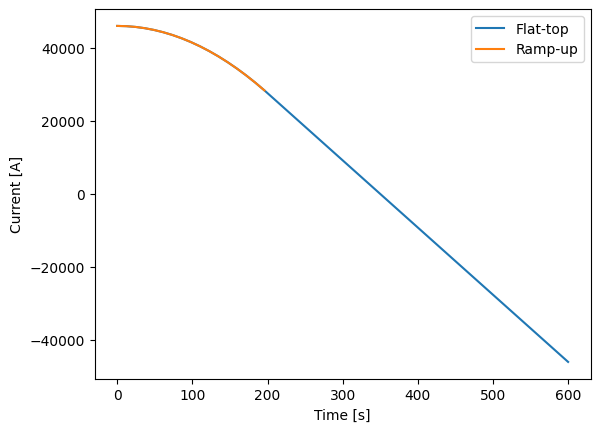

In [11]:
# plot whole profile as flat top
plt.plot(t_ * Ts, c_prof * imax, label="Flat-top")
# plot ramp up on top
# get time
tr_ = t_[(t_ * Ts) <= (Ts * rt)]
# get current
cr_ = c_prof[(t_ * Ts) <= (Ts * rt)]
plt.plot(tr_ * Ts, cr_ * imax, label="Ramp-up")
plt.xlabel("Time [s]")
plt.ylabel("Current [A]")
plt.legend(loc='upper right')

## Magnetic field

In [12]:
# create space to calculate the flux of the magnetic field
# the axis of the cs coil will be aliged with the origin
mesh_cs = np.meshgrid(np.linspace(-Rv, Rv, ng), np.linspace(-Rv, Rv, ng))
# get the points that lie inside the torus major radius
mesh_bool = np.sqrt(mesh_cs[0]**2 + mesh_cs[1]**2) < Rv
mesh_inside = []
for i in range(len(mesh_cs[0])):
    for j in range(len(mesh_cs[0][0])):
        # if the point is inside the circle
        if mesh_bool[i, j]:
            x = mesh_cs[0][i][j]
            y = mesh_cs[1][i][j]
            mesh_inside.append([x, y])
# turn the list into an array
mesh_inside = np.array(mesh_inside)
x = mesh_inside[:, 0]
y = mesh_inside[:, 1]

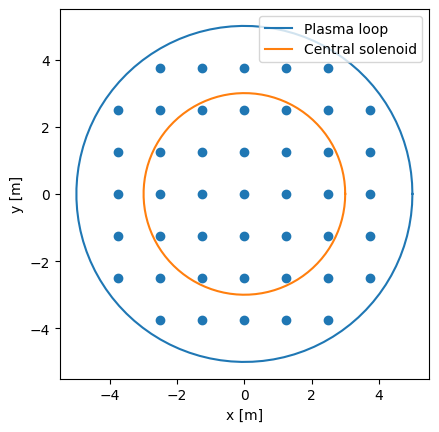

In [13]:
th_ = np.linspace(0, 2 * np.pi, 100)
xp = Rv * Rp * np.cos(th_)
yp = Rv * Rp * np.sin(th_)
xs = rcs * Rp * np.cos(th_)
ys = rcs * Rp * np.sin(th_)
plt.plot(xp, yp, label="Plasma loop")
plt.plot(xs, ys, label="Central solenoid")
plt.scatter(x, y)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc='upper right')
plt.gca().set_aspect("equal")
plt.show()

## CS definition

In [14]:
# create the central solenoid coil equation
def cs_eq (r, h, n): 
    # the eq of the coil is going to be parametrized in terms of the angle phi
    # create symbol of parameter
    p = sym.symbols('p')
    # create the domain of the parameter (dimensionless)
    # goes from 2pi to 0, meaning the current of the cs will flow clockwise
    # this will make the induced plasma current to flow anti
    d = np.array([0, 2 * np.pi])
    # create the coordinates of the coil
    x = r * sym.sin(n * p)
    y = -r * sym.cos(n * p)
    z = (h / (2 * np.pi)) * p - (h / 2)
    # create the loop vector
    l = sym.Matrix([x, y, z])
    # pack everything and return
    pack = [l, d, p]
    return pack
# get the (dimensionless) pack for our central solenoid
cs_pack = cs_eq (rcs, hcs, ncs)

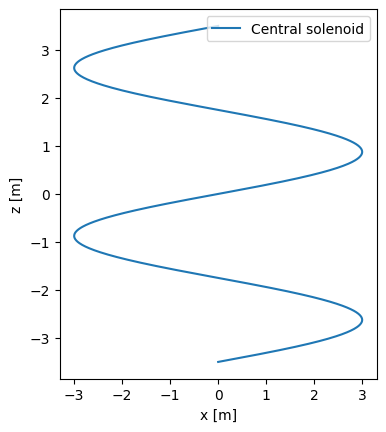

In [15]:
phi = np.linspace(0, 2 * np.pi, 1000)
# plot may not show an accurate number of loops (ncs), beware
x = rcs * np.sin(ncs * phi)
z = (hcs / (2 * np.pi)) * phi - (hcs / 2)
plt.plot(Rp * x, Rp * z, label="Central solenoid")
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.gca().set_aspect("equal")
plt.legend(loc='upper right')
plt.show()

## Biot-Savart law

In [16]:
# function to calculate the (dimensionless) magnetic field at a point (x, y, z), with biot-savart 
# generated by the coil described in the pack [vector, domain, parameter]
def b_field (pack, xp, yp, zp):
    # unpack the coil
    # function to describe loop
    l = pack[0]
    # domanin of integration
    d = pack[1]
    # parameter symbol
    s = pack[2]
    # create the vectors for biot-savart law
    xs, ys, zs = sym.symbols('xs, ys, zs')
    # position vector
    r = sym.Matrix([xs, ys, zs])
    # vector from coil to position
    rp = r - l
    # create integrand for biot-savart
    i = sym.diff(l, s).cross(rp)/rp.norm()**3
    # separate integrand into directions, and make them a function
    dbx = sym.lambdify([s, xs, ys, zs], i[0])
    dby = sym.lambdify([s, xs, ys, zs], i[1])
    dbz = sym.lambdify([s, xs, ys, zs], i[2])
    # integrate the function of each direction at a given point
    # which gives the corresponding field component
    bx = quad(dbx, d[0], d[1], args=(xp, yp, zp))[0]
    by = quad(dby, d[0], d[1], args=(xp, yp, zp))[0]
    bz = quad(dbz, d[0], d[1], args=(xp, yp, zp))[0]
    # pack the components into a vector and return
    field = np.array([bx, by, bz])
    return field

In [17]:
# calculate field at the center of the solenoid, in Teslas
b = ((mu0 * imax) / (4* np.pi * Rp)) * b_field(cs_pack, 0, 0, 0)
# notice the third component, corresponding to the z direction
print(b)

[-1.87392685e-02 -4.92671626e-13  1.25732893e+01]


/tmp/ipykernel_2171/4088499234.py:25: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  bx = quad(dbx, d[0], d[1], args=(xp, yp, zp))[0]


## Induced EMF

In [18]:
# calculate the field on every point inside of the torus major radius
# at the middle of the cs (z = 0)
B = []
for i in range(len(x)):
    xp = x[i]
    yp = y[1]
    zp = 0
    f = b_field(cs_pack, xp, yp, zp)
    B.append(f)
# convert it into array
B = np.array(B)

/tmp/ipykernel_2171/4088499234.py:25: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  bx = quad(dbx, d[0], d[1], args=(xp, yp, zp))[0]
/tmp/ipykernel_2171/4088499234.py:27: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  bz = quad(dbz, d[0], d[1], args=(xp, yp, zp))[0]
/tmp/ipykernel_2171/4088499234.py:26: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  by = quad(dby, d[0], d[1], args=(xp, yp, zp))[0]
/tmp/ipykernel_2171/4088499234.py:26: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  by

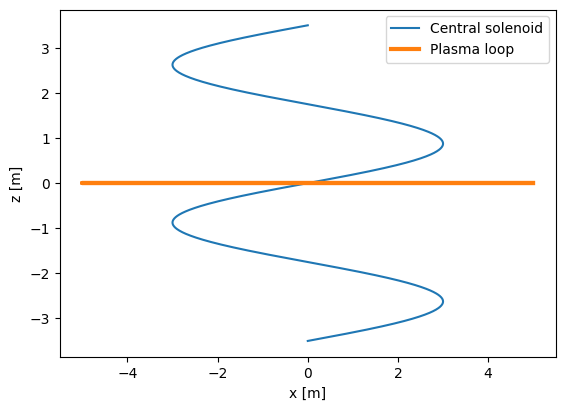

In [34]:
phi = np.linspace(0, 2 * np.pi, 1000)
cx = rcs * np.sin(ncs * phi)
cz = (hcs / (2 * np.pi)) * phi - (hcs / 2)
plt.plot(Rp * cx, Rp * cz, label="Central solenoid")
px = Rv * np.cos(phi)
pz = np.zeros(len(phi))
plt.plot(Rp * px, Rp * pz, label="Plasma loop", linewidth=3)
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.gca().set_aspect("equal")
plt.legend(loc='upper right')
plt.show()

## Field flux

In [20]:
# get the flux of the fild inside of the torus major radius
nf = len(B)
flux = np.sum(B[:, 2]) / nf

## Faraday's law

In [21]:
# get the change through time of the current of the cs
didt = np.gradient(c_prof) * nt

# get the induced emf
emf = didt * flux

## Current density

In [22]:
# dimensionless current density will be equal to dimensionless emf
J = emf

## CS-induced plasma current

In [23]:
# get plasma current, induced by cs
Ics = ((mu0 * imax * Rp * Acs) / (4 * np.pi * Ts * Res)) * emf

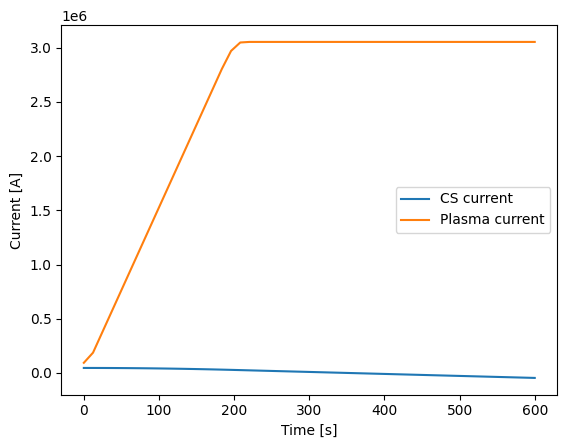

In [24]:
plt.plot(t_ * Ts, c_prof * imax, label='CS current')
plt.plot(t_ * Ts, Ics, label='Plasma current')
plt.xlabel("Time [s]")
plt.ylabel("Current [A]")
plt.legend()
plt.show()

#

# Bootstrap current

## Initialize space

In [60]:
# define coordinate ranges
# make them with plasma radius, as points outside it are unimportant
# need to ensure both have an odd number of points, to have a center point
if not int(n_side) % 2:
    x_ = np.linspace(-1, 1, int(n_side) + 1)
else:
    x_ = np.linspace(-1, 1, int(n_side))
if not int(m * n_side) % 2:
    y_ = np.linspace(-m, m, int(m * n_side) + 1)
else:
    y_ = np.linspace(-m, m, int(m * n_side))

# create meshgrid
x, y = np.meshgrid(x_, y_)

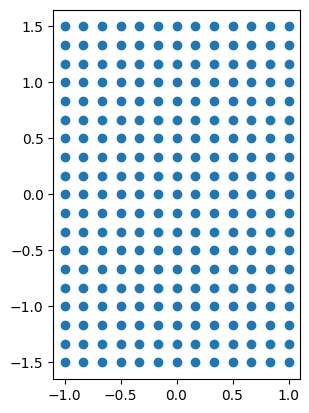

In [61]:
plt.gca().set_aspect("equal")
plt.scatter(Rp * x, Rp * y)
plt.show()

In [28]:
# plasma
# coord parametrized in polar
t = np.linspace(0, 2*np.pi, 100)
x_p = b_p * np.cos (t)
y_p = a_p * np.sin (t)

# vessel
# axes
a_v = m * rv
b_v = rv
# coord parametrized in polar
t = np.linspace(0, 2*np.pi, 100)
x_v = b_v * np.cos (t)
y_v = a_v * np.sin (t)

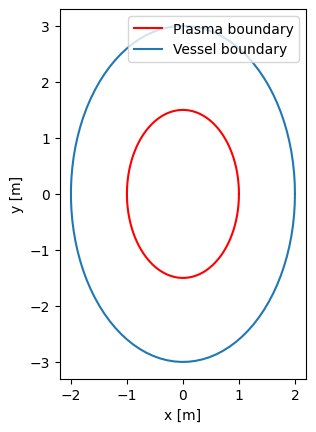

In [63]:
plt.gca().set_aspect("equal")
plt.plot(Rp * x_p, Rp * y_p, c="r", label="Plasma boundary")
plt.plot(Rp * x_v, Rp * y_v, label="Vessel boundary")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc="upper right")
plt.show()

In [66]:
# get points inside plasma boundary
# get distance from point to center
dp = np.sqrt(x**2 + y**2)
# get distance from center to boundary, for the same direction as a point
# direction for a given point
tp = np.arctan2(y / m, x)
# tp = np.arctan2(y, x)
# coords of boundary in that direction
xb = b_p * np.cos (tp)
yb = a_p * np.sin (tp)
# distance to boundary
db = np.sqrt(xb**2 + yb**2)
# see if point is inside or outside plasma boundary
b_bool = dp < db
# go through all the points, get the ones that are inside
p_inside = []
# also get the disance from center to bondary for each point
# and distance from center to point
# and direction for each point
# useful for later
d_bounds = []
d_points = []
t_points = []
for i in range(len(x)):
    for j in range(len(x[0])):
        if b_bool[i, j]:
            # point inside boundary
            x_in = x[i][j]
            y_in = y[i][j]
            p_inside.append([x_in, y_in])
            # distance to boundary
            d_bound = db[i][j]
            d_bounds.append(d_bound)
            # distance to point
            d_point = dp[i][j]
            d_points.append(d_point)
            # direction of point
            t_point = tp[i][j]
            t_points.append(t_point)
# turn lists into arrays
p_inside = np.array(p_inside)            
d_bounds = np.array(d_bounds)
d_points = np.array(d_points)
t_points = np.array(t_points)
# overwrite x and y arrays
x = p_inside[:, 0]
y = p_inside[:, 1]

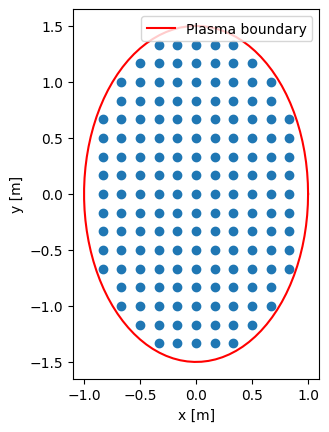

In [67]:
plt.gca().set_aspect("equal")
plt.plot(Rp * x_p, Rp * y_p, c="r", label="Plasma boundary")
plt.scatter(Rp * x, Rp * y)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc="upper right")
plt.show()

## Particle density gradient

In [69]:
# get n0
n0 = 1 / np.sum(1 - (d_points / d_bounds))

# direction to the center at each points
# make norms a column vector
pnorm = np.array([d_points]).T
# for the center point, it will give nan
rhat = p_inside * (1 / pnorm)
# replace the nan by 0
rhat[np.isnan(rhat[:, 0])] = np.array([0, 0])

# get (dimensionless) particle gradient at each point
# same thing as above
bnorm = np.array([d_bounds]).T
ngrad = -(n0 / bnorm) * rhat

# get particle densities
n = n0 * (1 - (d_points / d_bounds))

/tmp/ipykernel_2171/3870269893.py:8: RuntimeWarning: divide by zero encountered in divide
  rhat = p_inside * (1 / pnorm)
/tmp/ipykernel_2171/3870269893.py:8: RuntimeWarning: invalid value encountered in multiply
  rhat = p_inside * (1 / pnorm)


## Pressure gradient

In [71]:
# get pressure gradient at each point
# normalized, it will be the same as the particle gradient
pgrad = ngrad

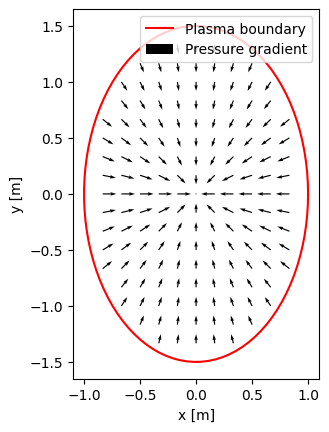

In [72]:
plt.gca().set_aspect("equal")
plt.plot(Rp * x_p, Rp * y_p, c="r", label="Plasma boundary")
plt.quiver(Rp * x, Rp * y, pgrad[:, 0], pgrad[:, 1], label="Pressure gradient")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc="upper right")
plt.show()

## Current density

In [73]:
# get (dimensionless) current densities, induced by solenoid
# one density map per moment in time
jc = []
for Js in J:
    curr = Js * n
    jc.append(curr)
jc = np.array(jc)

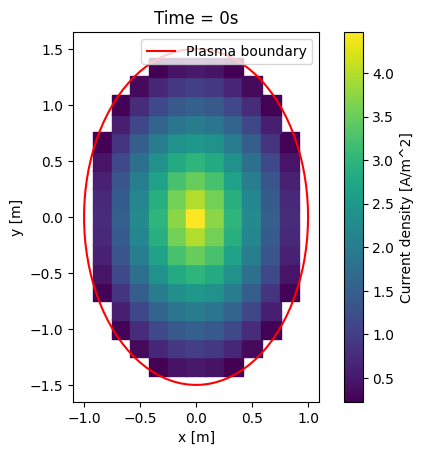

In [75]:
plt.gca().set_aspect("equal")
# heatmap with current data organization
plt.plot(x_p * Rp, y_p * Rp, c="r", label="Plasma boundary")
D = (mu0 * imax * Rp) / (4 * np.pi * Ts * eta * Lp)
map = plt.scatter(x * Rp, y * Rp, 
                 c= D * jc[0], marker = "s", s = 200)
cbar = plt.colorbar(map)
cbar.set_label("Current density [A/m^2]")
plt.title("Time = 0s")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc="upper right")

## Poloidal magnetic field

### Create ellipse parameters 

In [76]:
# for each point, get perimeter of inner elipse
# and its area
# and list of point that lie inside of it
# and the vector tangent to its surface (at the point)
# ellipse parameters
te = np.round(np.arctan2(y / m, x), 7)
be = np.round(np.sqrt(d_points**2 / (np.cos(te)**2 + m**2 * np.sin(te)**2)), 7)
ae = np.round(m * be, 7)
# elipse perimeter
p_ellipse = np.round(2 * np.pi * np.sqrt((ae**2 + be**2) / 2), 7)
# area
a_ellipse = np.round(np.pi * ae * be, 7)
# points inside
e_inside = []
# for each different ellipse
for i in range(len(p_ellipse)):
    # distance to ellipse boundary, in each point's direction
    de = np.round(np.sqrt(be[i]**2 * np.cos(t_points)**2 + ae[i]**2 * np.sin(t_points)**2), 7)
    # array of points that are inside that ellipse
    ins = np.round(d_points, 7) < de
    # add the array to the list
    e_inside.append(ins)
# turn list into array 
e_inside = np.array(e_inside)
# tangent vector
xtang = -be * np.sin(te)
ytang = ae * np.cos(te)
tang = np.vstack((xtang, ytang)).T
ntang = np.array([np.sqrt(xtang**2 + ytang**2)]).T
e_tang = tang / ntang
# make small values equal to 0
e_tang[np.where(abs(e_tang) < 1e-16)] = 0
# make center values equal to 0, instead of nan
e_tang[np.isnan(e_tang[:, 0])] = [0, 0]

/tmp/ipykernel_2171/505930461.py:30: RuntimeWarning: invalid value encountered in divide
  e_tang = tang / ntang


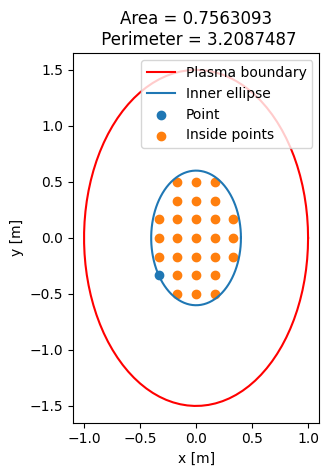

In [77]:
# choose ellipse number
e = 55
# create ellipse borders
te_ = np.linspace(0, 2 * np.pi, 100)
xe = be[e] * np.cos(te_)
ye = ae[e] * np.sin(te_)
plt.gca().set_aspect("equal")
plt.plot(Rp * x_p, Rp * y_p, c="r", label="Plasma boundary")
# plot inner ellipse
plt.plot(Rp * xe, Rp * ye, label="Inner ellipse")
# plot current point
plt.scatter(Rp * x[e], Rp * y[e], label="Point")
# plot points that are inside of ellipse
plt.scatter(Rp * x[e_inside[e]], Rp * y[e_inside[e]], label="Inside points")
# show data
plt.title("Area = "+str(a_ellipse[e])+"\n Perimeter = "+str(p_ellipse[e]))
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc='upper right')
plt.show()

### Ampère's law

In [79]:
# function to get poloidal magnetic field at a point, given by index
def b_poloidal (i, j):
    # get perimeter of corresponding elipse
    p = p_ellipse[i]
    # get the area
    a = a_ellipse[i]
    # get direction of field (tangent)
    d = e_tang[i]
    # get list of points inside of ellipse
    ins = e_inside[i]
    # calculate current with points that are inside
    I = 0
    for k in range(len(j)):
        if ins[k]:
            I += j[k]
    field = ((I * a) / p) * d
    return field

## Bootstrap current density

In [80]:
# function to calculate the bootstrap current at a point
def bootstrap (bfield, pgrad):
    b2 = bfield[0]**2 + bfield[1]**2
    curr = np.cross(bfield, pgrad) / b2
    return curr

In [81]:
# create total current array
# initially equal to the current induced by the cs
jt = np.copy(jc)
# indexes of jt
jti = np.arange(0, len(jt), 1)
# dimension of the overall current density
Dj = (mu0 * imax * Rp * Acs * A) / (4 * np.pi * Ts * eta * Lp)
# factor to multiply bootstrap current with
# so that it can be added normally to the overall current density
Db = (ne * kb * T) / (mu0 * Rp * Dj**2)

In [82]:
# go through all moments in time
# through all the points, calculating the field and the bootstrap
# and adding it to the next moment, to repeat
# go from first to penultimate moment in time
for i in range(len(jt) - 1):
    # for all points inside the plasma
    for k in range(len(p_inside)):
        # skip the center point
        if x[k] == 0 and y[k] == 0:
            continue
        # get corresponding current map
        j = jt[i]
        # get pressure gradient
        pg = pgrad[k]
        # get magnetic field
        bf = b_poloidal(k, j)
        # get bootstrap current 
        jb = bootstrap(bf, pg)
        # add the bootstrap current to the same point
        # to all moments after right now
        jt[jti > i, k] += Db * jb

/tmp/ipykernel_2171/2433208306.py:4: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  curr = np.cross(bfield, pgrad) / b2


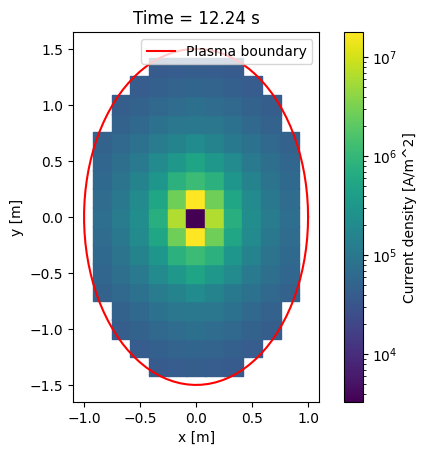

In [84]:
plt.gca().set_aspect("equal")
plt.plot(x_p * Rp, y_p * Rp, c="r", label="Plasma boundary")
map = plt.scatter(x * Rp, y * Rp, 
                 c= Dj * jt[1], marker = "s", s = 200,
                 norm = LogNorm())
cbar = plt.colorbar(map)
cbar.set_label("Current density [A/m^2]")
plt.title("Time = "+str(round(t_[1] * Ts, 2))+" s")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend(loc="upper right")
plt.show()

## Results

### Total plasma current

In [85]:
# get total current through time
ct = np.sum(jt, axis=1)

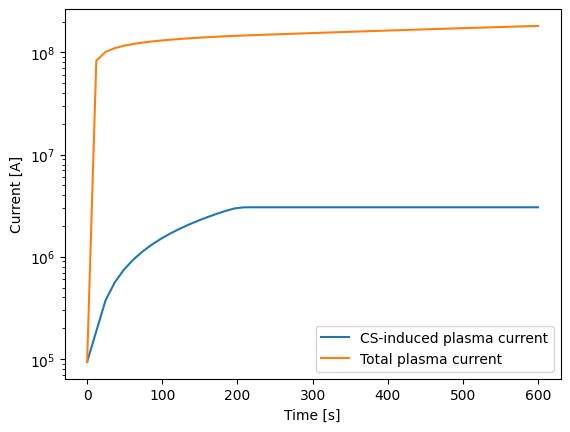

In [92]:
plt.plot(t_ * Ts, Ics, label="CS-induced plasma current")
plt.plot(t_ * Ts, ct * Dj, label="Total plasma current")
plt.yscale("log")
plt.xlabel("Time [s]")
plt.ylabel("Current [A]")
plt.legend(loc='lower right')

### Bootstrap plasma current

In [93]:
# get the current that is only bootstrap 
cb = (Dj * ct) - Ics

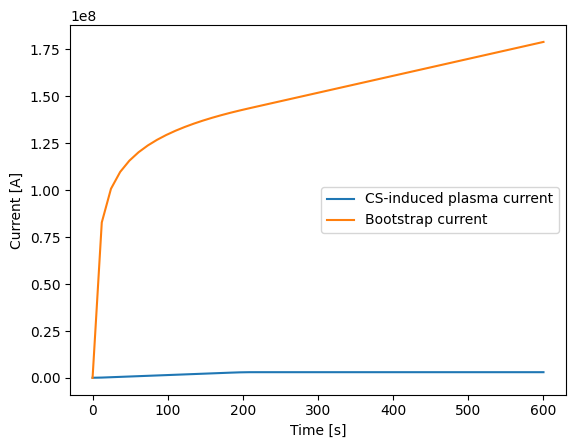

In [94]:
plt.plot(t_ * Ts, Ics, label="CS-induced plasma current")
plt.plot(t_ * Ts, cb, label="Bootstrap current")
plt.xlabel("Time [s]")
plt.ylabel("Current [A]")
plt.legend(loc='center right')

### Fraction of total current

In [97]:
# fraction of total current due to bootstrap
# taken for the last moment of the simulation
f = cb[-1] / (Dj * ct[-1])
print(f)

0.9832205917596026


### Decrease of bootstrap current

In [96]:
# the bootstrap current decreases as the magnitude of the magnetic field increases
# but it does so very slowly
gc = np.gradient(cb)
# the amount by which the bootstrap current increases is decreasing each time
print(gc[-11:-1])

[1104507.88518913 1104458.15363605 1104409.13046871 1104360.80047905
 1104313.14889663 1104266.16137277 1104219.82396556 1104174.12312521
 1104129.04568027 1104084.57882445]
